In [1]:
import pandas as pd


In [2]:
df = pd.read_excel(r"C:\Users\Vanithav\OneDrive\Microsoft Copilot Chat Files\Desktop\Documents\data analytics\Vrinda  Dataset project.xlsx")
print(df.head())

   index             Order ID  Cust ID Gender  Age Age Group       Date  \
0      1  171-1029312-3038738  1029312  Women   44     Adult 2022-12-04   
1      2  405-2183842-2225946  2183842  Women   29  Teenager 2022-12-04   
2      3  171-1641533-8921966  1641533  Women   67    Senior 2022-12-04   
3      4  404-7490807-6300351  7490807  Women   20  Teenager 2022-12-04   
4      5  403-9293516-4577154  9293516  Women   62    Senior 2022-12-04   

      Month     Status Channel   ... Category Size Qty  currency Amount  \
0  December  Delivered   Myntra  ...    kurta  XXL   1       INR    376   
1  December  Delivered     Ajio  ...      Set    L   1       INR   1449   
2  December  Delivered   Myntra  ...      Set    S   1       INR    453   
3  December  Delivered   Amazon  ...      Set    M   1       INR    729   
4  December  Delivered   Myntra  ...    kurta  XXL   1       INR    544   

   ship-city   ship-state ship-postal-code  ship-country    B2B  
0     MOHALI       PUNJAB       

In [6]:
print(df.shape)

(31047, 21)


In [7]:
# Missing values
print(df.isnull().sum())

index               0
Order ID            0
Cust ID             0
Gender              0
Age                 0
Age Group           0
Date                0
Month               0
Status              0
Channel             0
SKU                 0
Category            0
Size                0
Qty                 0
currency            0
Amount              0
ship-city           0
ship-state          0
ship-postal-code    0
ship-country        0
B2B                 0
dtype: int64


In [8]:
#Duplicate values
print("Duplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


In [9]:
#Remove duplicates
df = df.drop_duplicates()
print("New Shape:", df.shape)

New Shape: (31047, 21)


In [10]:
#Remove extra space from colm
df.columns = df.columns.str.strip()
print(df.columns.tolist())

['index', 'Order ID', 'Cust ID', 'Gender', 'Age', 'Age Group', 'Date', 'Month', 'Status', 'Channel', 'SKU', 'Category', 'Size', 'Qty', 'currency', 'Amount', 'ship-city', 'ship-state', 'ship-postal-code', 'ship-country', 'B2B']


In [11]:
#check the data
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 31047 entries, 0 to 31046
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   index             31047 non-null  int64         
 1   Order ID          31047 non-null  str           
 2   Cust ID           31047 non-null  int64         
 3   Gender            31047 non-null  str           
 4   Age               31047 non-null  int64         
 5   Age Group         31047 non-null  str           
 6   Date              31047 non-null  datetime64[us]
 7   Month             31047 non-null  str           
 8   Status            31047 non-null  str           
 9   Channel           31047 non-null  str           
 10  SKU               31047 non-null  str           
 11  Category          31047 non-null  str           
 12  Size              31047 non-null  str           
 13  Qty               31047 non-null  int64         
 14  currency          31047 non-null 

In [9]:
print("Total Sales =", df["Amount"].sum())

Total Sales = 21176377


In [12]:
print("Average Sales =", df["Amount"].mean())


Average Sales = 682.0748220439978


In [13]:
df["Date"] = pd.to_datetime(df["Date"])
print(df)


       index             Order ID  Cust ID Gender  Age Age Group       Date  \
0          1  171-1029312-3038738  1029312  Women   44     Adult 2022-12-04   
1          2  405-2183842-2225946  2183842  Women   29  Teenager 2022-12-04   
2          3  171-1641533-8921966  1641533  Women   67    Senior 2022-12-04   
3          4  404-7490807-6300351  7490807  Women   20  Teenager 2022-12-04   
4          5  403-9293516-4577154  9293516  Women   62    Senior 2022-12-04   
...      ...                  ...      ...    ...  ...       ...        ...   
31042  31043  405-4724097-1016369  4724097    Men   60    Senior 2022-01-06   
31043  31044  405-4724097-1016369  4724097    Men   34     Adult 2022-01-06   
31044  31045  408-3572295-5992330  3572295    Men   29  Teenager 2022-01-06   
31045  31046  405-1423498-9705162  1423498    Men   46     Adult 2022-01-06   
31046  31047  408-4694875-8249153  4694875    Men   36     Adult 2022-01-06   

          Month     Status   Channel  ...       Cat

In [14]:
df["Month"] = df["Date"].dt.to_period("M").astype(str)
print(df)


       index             Order ID  Cust ID Gender  Age Age Group       Date  \
0          1  171-1029312-3038738  1029312  Women   44     Adult 2022-12-04   
1          2  405-2183842-2225946  2183842  Women   29  Teenager 2022-12-04   
2          3  171-1641533-8921966  1641533  Women   67    Senior 2022-12-04   
3          4  404-7490807-6300351  7490807  Women   20  Teenager 2022-12-04   
4          5  403-9293516-4577154  9293516  Women   62    Senior 2022-12-04   
...      ...                  ...      ...    ...  ...       ...        ...   
31042  31043  405-4724097-1016369  4724097    Men   60    Senior 2022-01-06   
31043  31044  405-4724097-1016369  4724097    Men   34     Adult 2022-01-06   
31044  31045  408-3572295-5992330  3572295    Men   29  Teenager 2022-01-06   
31045  31046  405-1423498-9705162  1423498    Men   46     Adult 2022-01-06   
31046  31047  408-4694875-8249153  4694875    Men   36     Adult 2022-01-06   

         Month     Status   Channel  ...       Cate

In [15]:
monthly_sales = df.groupby("Month")["Amount"].sum()
print(df)


       index             Order ID  Cust ID Gender  Age Age Group       Date  \
0          1  171-1029312-3038738  1029312  Women   44     Adult 2022-12-04   
1          2  405-2183842-2225946  2183842  Women   29  Teenager 2022-12-04   
2          3  171-1641533-8921966  1641533  Women   67    Senior 2022-12-04   
3          4  404-7490807-6300351  7490807  Women   20  Teenager 2022-12-04   
4          5  403-9293516-4577154  9293516  Women   62    Senior 2022-12-04   
...      ...                  ...      ...    ...  ...       ...        ...   
31042  31043  405-4724097-1016369  4724097    Men   60    Senior 2022-01-06   
31043  31044  405-4724097-1016369  4724097    Men   34     Adult 2022-01-06   
31044  31045  408-3572295-5992330  3572295    Men   29  Teenager 2022-01-06   
31045  31046  405-1423498-9705162  1423498    Men   46     Adult 2022-01-06   
31046  31047  408-4694875-8249153  4694875    Men   36     Adult 2022-01-06   

         Month     Status   Channel  ...       Cate

In [16]:
print(monthly_sales)

Month
2022-01    1820601
2022-02    1875932
2022-03    1928066
2022-04    1829263
2022-05    1797822
2022-06    1750966
2022-07    1772300
2022-08    1808505
2022-09    1688871
2022-10    1666662
2022-11    1615356
2022-12    1622033
Name: Amount, dtype: int64


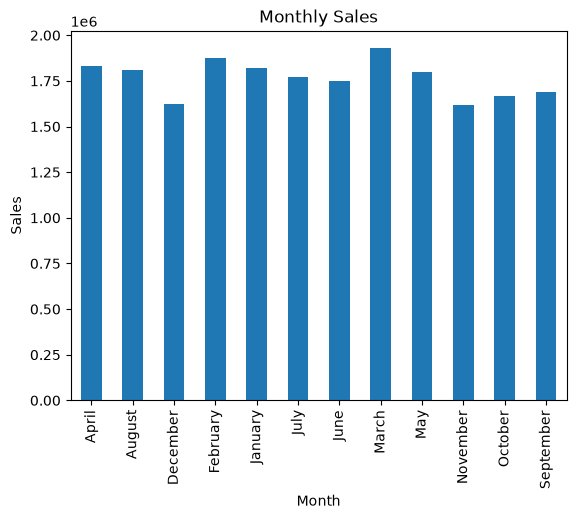

In [3]:
#visualization
#monthly sales
import matplotlib.pyplot as plt
monthly_sales = df.groupby("Month")["Amount"].sum()
monthly_sales.plot(kind="bar")
plt.title("Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.show()



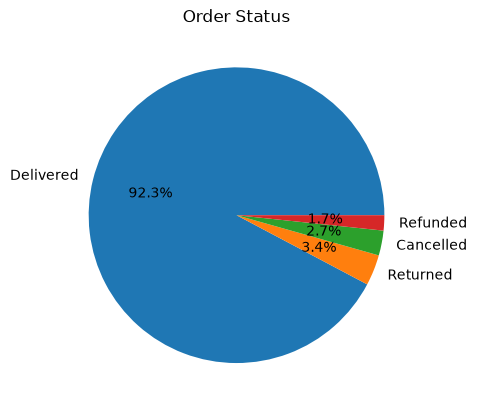

In [18]:
#Order Status
df["Status"].value_counts().plot(kind="pie",autopct="%1.1f%%")
plt.title("Order Status")
plt.ylabel("")
plt.show()

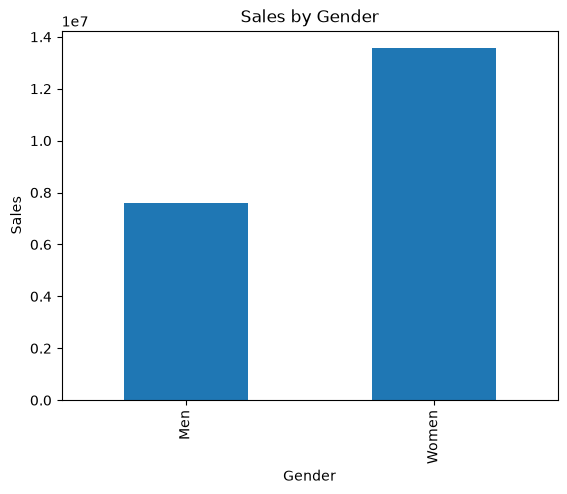

In [19]:
#Sales by Gender
gender_sales = df.groupby("Gender")["Amount"].sum()
gender_sales.plot(kind="bar")
plt.title("Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Sales")
plt.show()


Category
Set              10507546
kurta             4959377
Western Dress     3148836
Top               1186199
Saree             1010471
Ethnic Dress       195256
Blouse             140888
Bottom              27804
Name: Amount, dtype: int64


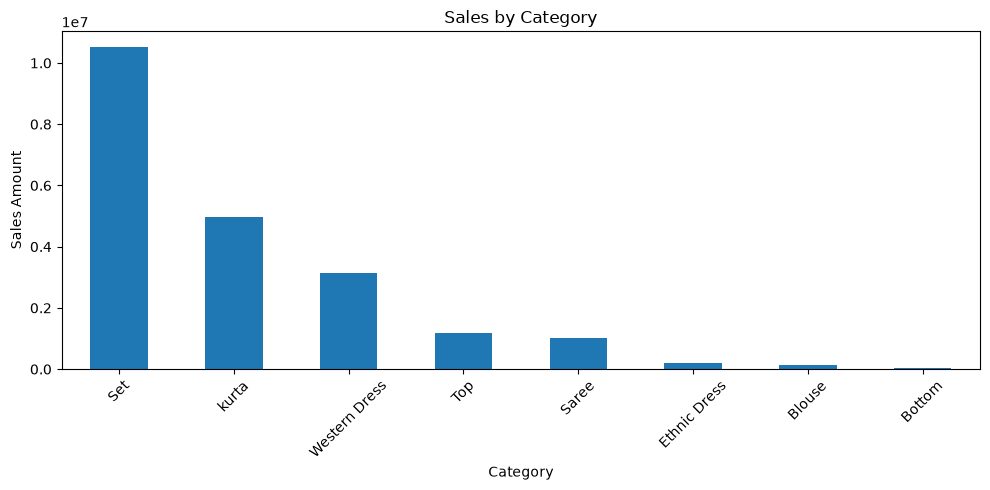

In [20]:
# Sales by Category
category_sales = df.groupby("Category")["Amount"].sum().sort_values(ascending=False)
print(category_sales)
category_sales.plot(kind="bar", figsize=(10, 5))
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

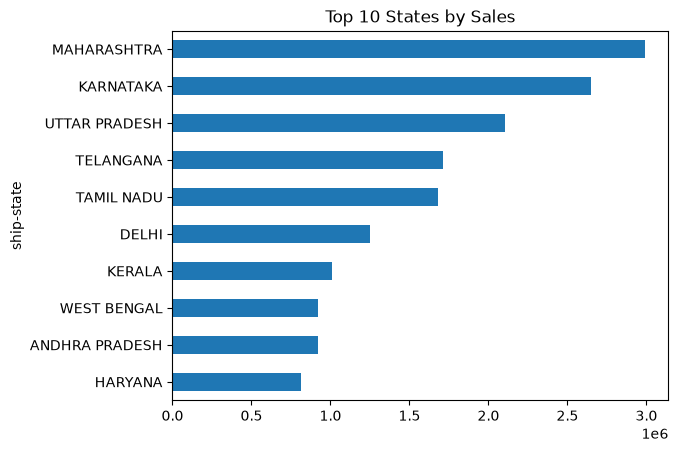

In [21]:
# Top 10 States by Sales
state_sales = (
    df.groupby("ship-state")["Amount"]
    .sum()
    .sort_values()
    .tail(10)
)
state_sales.plot(kind="barh")
plt.title("Top 10 States by Sales")
plt.show()

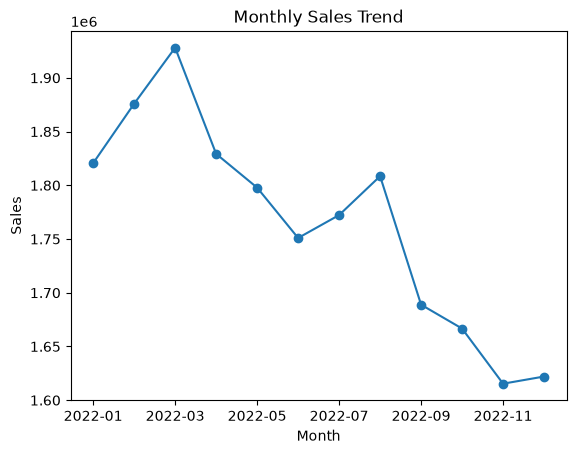

In [22]:
#Monthly Trend
monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.show()




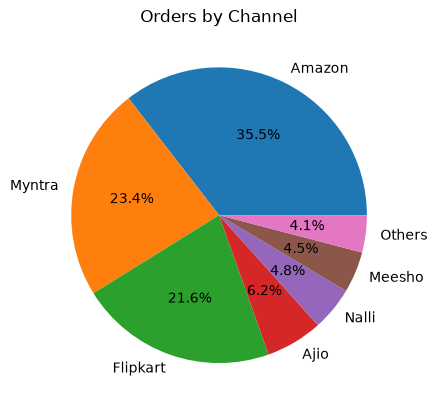

In [23]:
#Orders by Channel 
df["Channel"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)
plt.title("Orders by Channel")
plt.ylabel("")
plt.show()

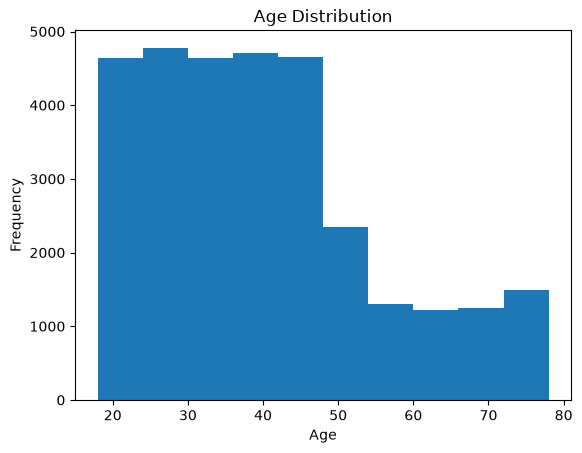

In [24]:
#Age distribution
df["Age"].plot(
    kind="hist",
    bins=10
)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.show()


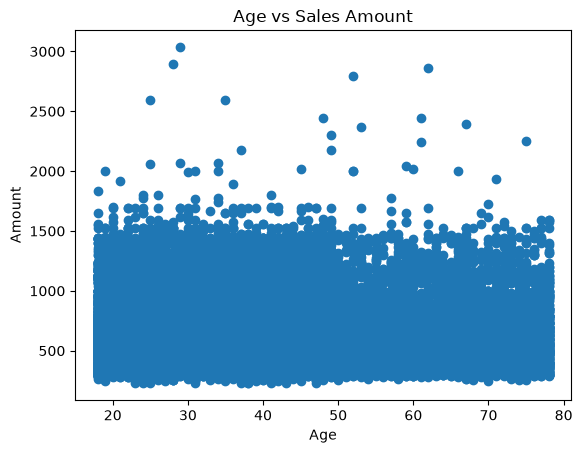

In [30]:
#Age VS Amount
plt.scatter(
    df["Age"],
    df["Amount"]
)
plt.title("Age vs Sales Amount")
plt.xlabel("Age")
plt.ylabel("Amount")
plt.show()

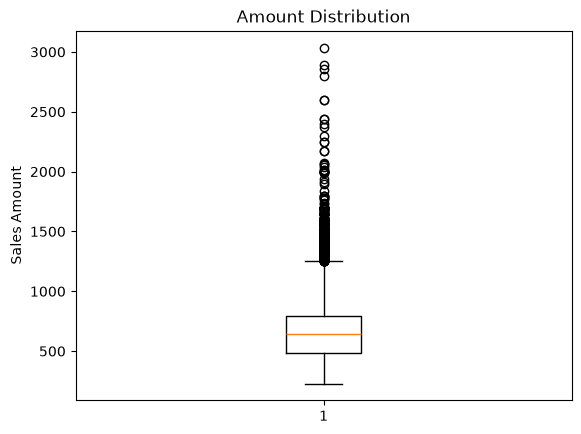

In [25]:
#Amount Distribution
plt.boxplot(df["Amount"])
plt.title("Amount Distribution")
plt.ylabel("Sales Amount")
plt.show()